# Phân tích và dự đoán bệnh tái nhập viện với bệnh tiểu đường


## 1. Cài đặt và kiểm tra dữ liệu

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", palette="deep")
sns.set_context(
    "notebook",
    font_scale=1.3,
    rc={
        "axes.titlesize": 20,
        "axes.labelsize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 12,
        "figure.titlesize": 19,
    },
)

DATA_PATH = Path("src/data/diabetic_data.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../src/data/diabetic_data.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Không tìm thấy src/data/diabetic_data.csv tại thư mục hiện tại.")

raw_data = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Kích thước dữ liệu: {raw_data.shape[0]:,} dòng x {raw_data.shape[1]} cột")
display(raw_data.head())
print("\nKiểu dữ liệu:")
display(raw_data.dtypes.rename("dtype").to_frame())

Kích thước dữ liệu: 101,766 dòng x 50 cột


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



Kiểu dữ liệu:


,dtype
encounter_id,int64
patient_nbr,int64
race,object
gender,object
age,object
weight,object
admission_type_id,int64
discharge_disposition_id,int64
admission_source_id,int64
time_in_hospital,int64


## 2. Phân bổ thuộc tính

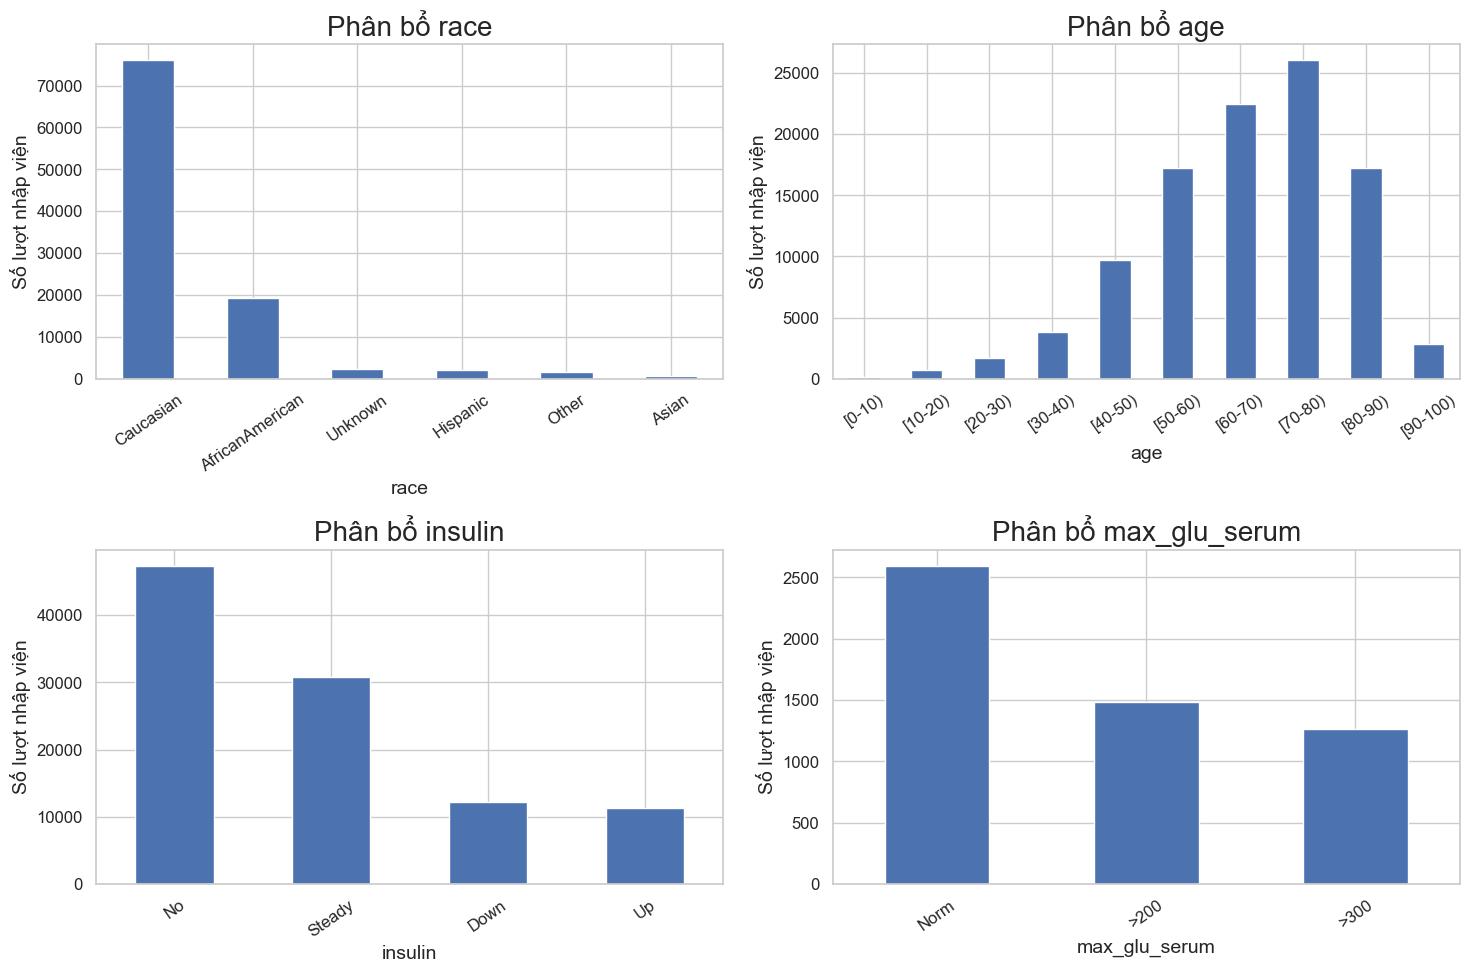

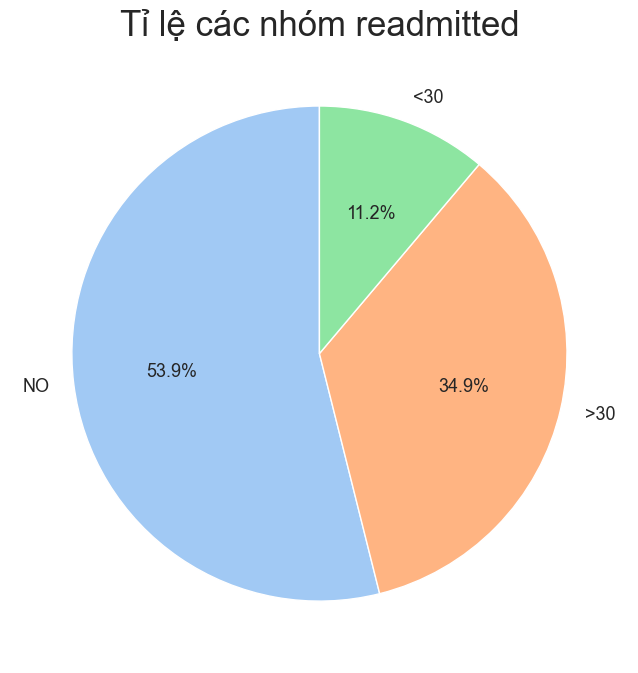

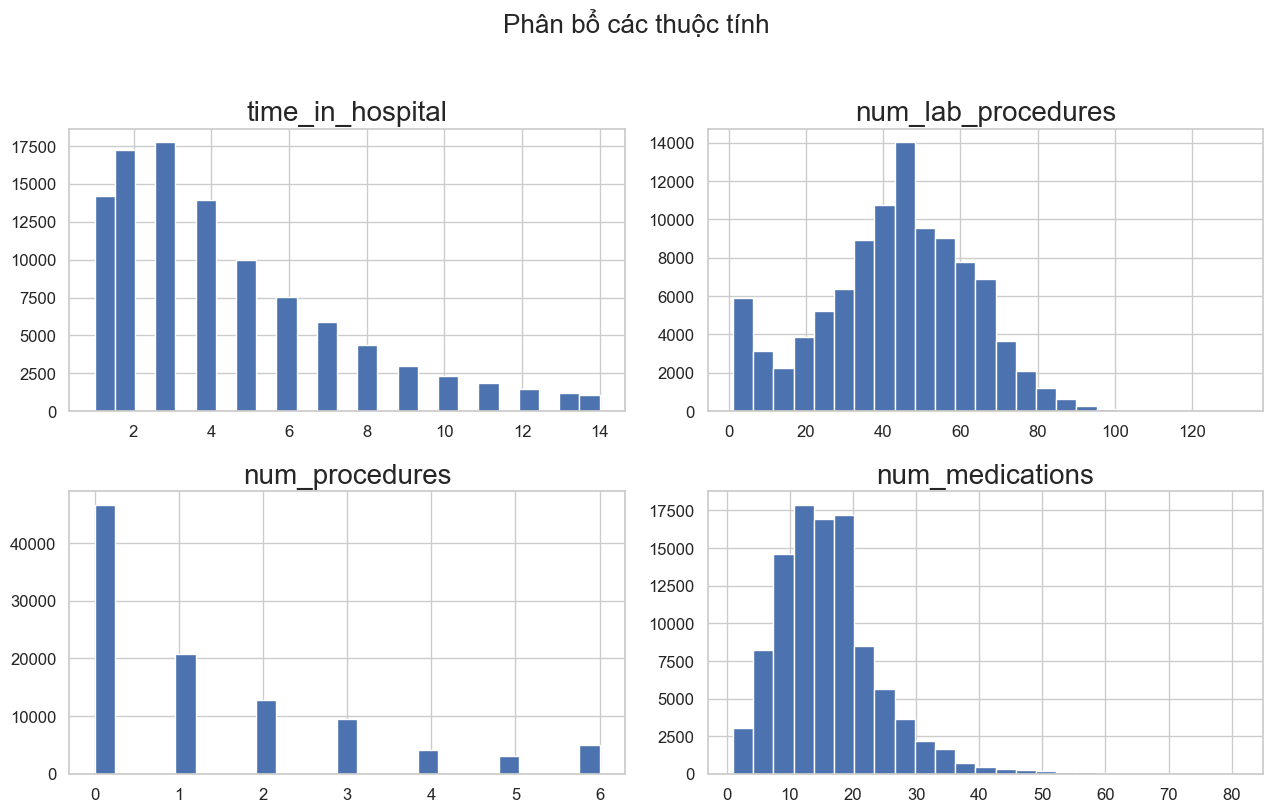

In [3]:
distribution_columns = ["race", "age", "insulin", "max_glu_serum"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for column, ax in zip(distribution_columns, axes.flat):
    values = raw_data[column].replace("?", "Unknown")
    counts = values.value_counts()
    if column == "age":
        counts = counts.reindex(values.drop_duplicates().tolist(), fill_value=0)
    else:
        counts = counts.head(12)
    counts.plot(kind="bar", ax=ax, color=sns.color_palette("deep")[0])
    ax.set_title(f"Phân bổ {column}")
    ax.set_xlabel(column, fontsize=14)
    ax.set_ylabel("Số lượt nhập viện")
    ax.tick_params(axis="x", rotation=35, labelsize=12)
    ax.tick_params(axis="y", labelsize=12)
fig.tight_layout()
plt.show()

readmission_counts = raw_data["readmitted"].value_counts()
fig, ax = plt.subplots(figsize=(7, 7))
readmission_counts.plot(
    kind="pie", autopct="%1.1f%%", startangle=90, ax=ax,
    colors=sns.color_palette("pastel", len(readmission_counts)),
    textprops={"fontsize": 13},
)
ax.set_title("Tỉ lệ các nhóm readmitted", fontsize=25,)
ax.set_ylabel("", fontsize=20)
plt.tight_layout()
plt.show()

numeric_distribution_columns = [
    "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications"
]
raw_data[numeric_distribution_columns].hist(bins=25, figsize=(13, 8), layout=(2, 2))
plt.suptitle("Phân bổ các thuộc tính", y=1.02)
plt.tight_layout()
plt.show()

## 3. Ma trận tương quan

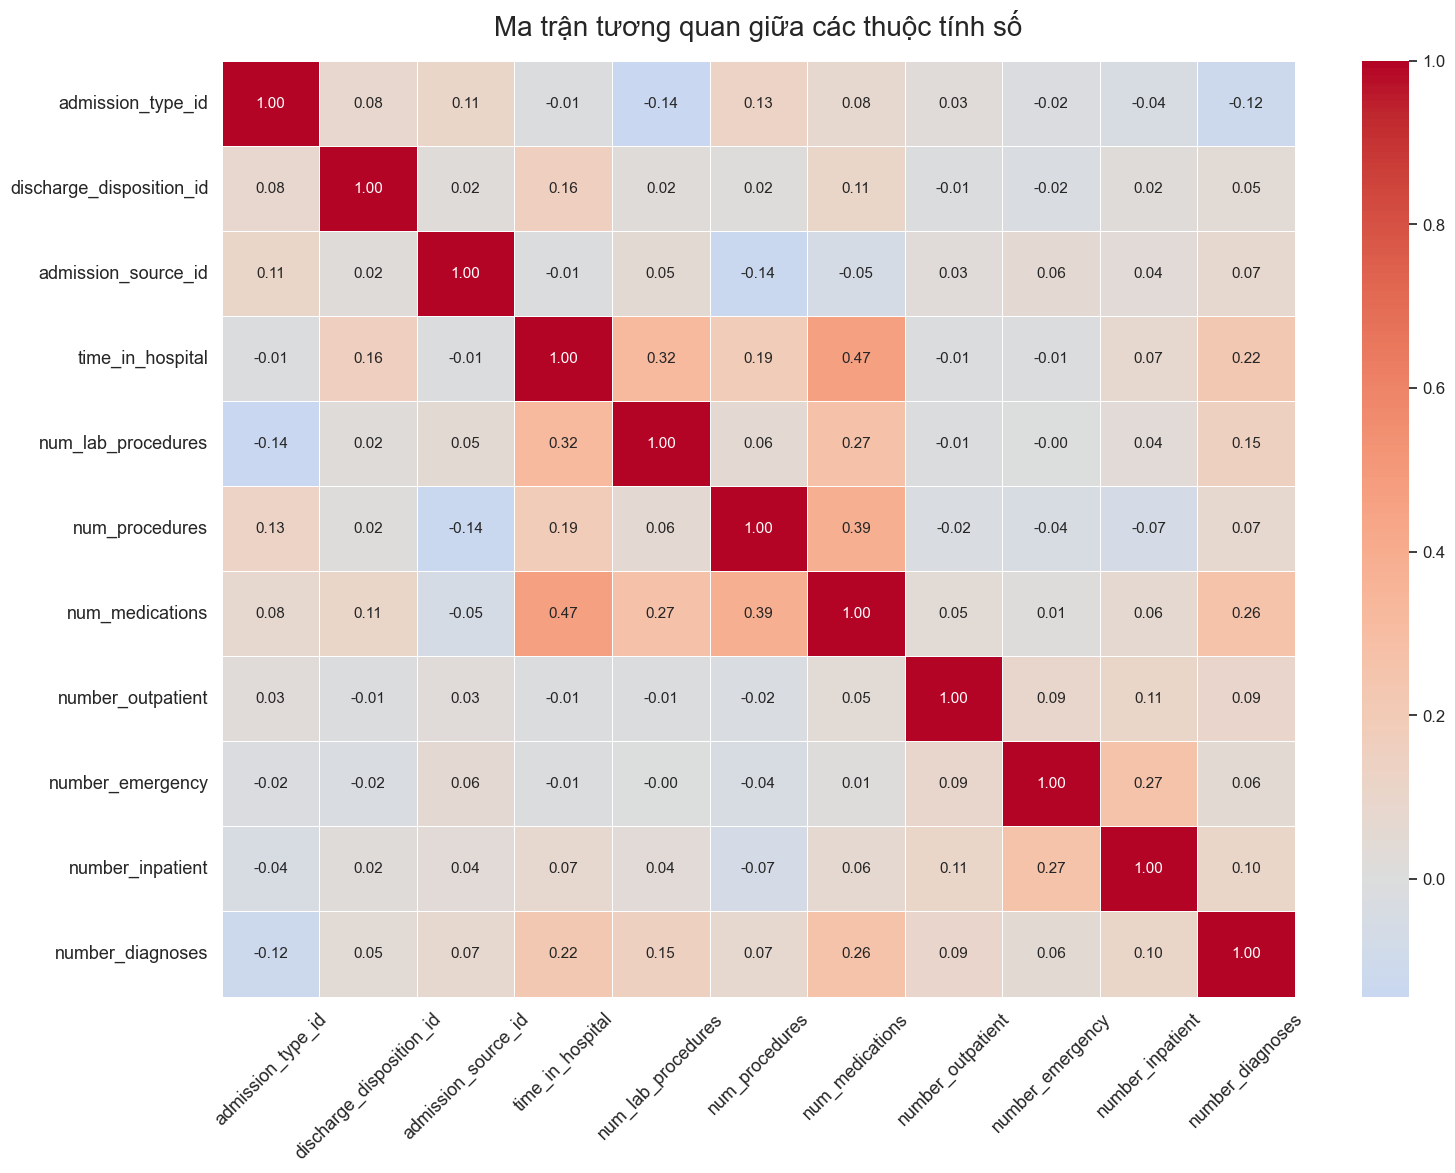

In [4]:
numeric_data = raw_data.select_dtypes(include="number").drop(
    columns=["encounter_id", "patient_nbr"], errors="ignore"
)
correlation = numeric_data.corr()
fig, ax = plt.subplots(figsize=(16, 12))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 11},
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Ma tr\u1eadn t\u01b0\u01a1ng quan gi\u1eefa c\u00e1c thu\u1ed9c t\u00ednh s\u1ed1", fontsize=20, pad=18)
ax.tick_params(axis="x", labelsize=13, rotation=45)
ax.tick_params(axis="y", labelsize=13, rotation=0)
plt.tight_layout()
plt.show()


diag_1, diag_2, diag_3 lần lượt lưu mã chẩn đoán chính, chẩn đoán thứ hai và chẩn đoán thứ ba.

Các giá trị quan sát được là mã ICD-9-CM ở dạng chuỗi. Trong đó, nhóm mã V (ví dụ: V57, liên quan đến chăm sóc và phục hồi chức năng) và nhóm mã E cũng là những mã chẩn đoán hợp lệ.

Vì mã chẩn đoán là thuộc tính phân loại (categorical), không phải đại lượng đo lường, nên việc thay thế các giá trị thiếu bằng giá trị trung bình là không phù hợp và không có ý nghĩa thống kê.

Do đó, các mã chẩn đoán hợp lệ được giữ nguyên và mã hóa bằng phương pháp One-Hot Encoding. Những giá trị ? được xem là dữ liệu khuyết (missing values) và được xử lý tương ứng.

## 4. Làm sạch dữ liệu và mã hóa target

192849
race                  2273
weight               98569
payer_code           40256
medical_specialty    49949
diag_1                  21
diag_2                 358
diag_3                1423
dtype: int64


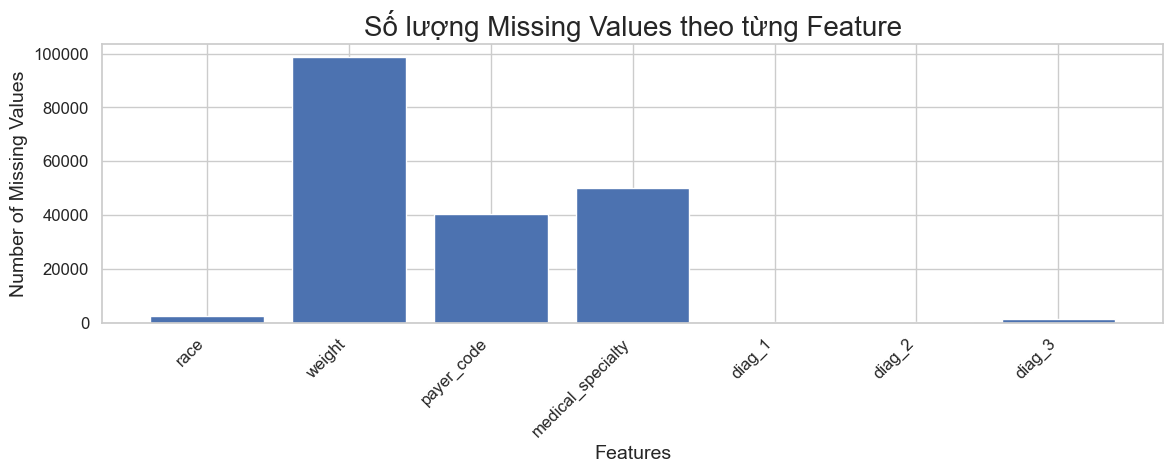

encounter_id                0
patient_nbr                 0
race                        0
gender                      0
age                         0
weight                      0
admission_type_id           0
discharge_disposition_id    0
admission_source_id         0
time_in_hospital            0
payer_code                  0
medical_specialty           0
num_lab_procedures          0
num_procedures              0
num_medications             0
number_outpatient           0
number_emergency            0
number_inpatient            0
diag_1                      0
diag_2                      0
diag_3                      0
number_diagnoses            0
max_glu_serum               0
A1Cresult                   0
metformin                   0
repaglinide                 0
nateglinide                 0
chlorpropamide              0
glimepiride                 0
acetohexamide               0
glipizide                   0
glyburide                   0
tolbutamide                 0
pioglitazo

In [17]:
data = raw_data.copy()
placeholder_count = int((data == "?").sum().sum())# Xử lý ? sang Null
print(placeholder_count)

missing_counts = (data == "?").sum()
print(missing_counts[missing_counts > 0])
missing_counts = missing_counts[missing_counts > 0]
plt.figure(figsize=(12, 5))
plt.bar(missing_counts.index, missing_counts.values)
plt.title("Số lượng Missing Values theo từng Feature")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

data.replace("?", np.nan, inplace=True)

print(data[data["weight"]=="?"].count())
data.drop(columns=["weight"], inplace=True)# Bỏ cột weight do missing quá nhiều


target = data["readmitted"].astype(str).str.strip().str.upper().ne("NO").astype("int8")
patient_groups = data["patient_nbr"].copy()
features = data.drop(columns=["readmitted", "encounter_id", "patient_nbr"])
features.info()

numeric_features = features.select_dtypes(include="number").columns.tolist()
categorical_features = features.select_dtypes(exclude="number").columns.tolist()

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_indices, test_indices = next(splitter.split(features, target, groups=patient_groups))
X_train, X_test = features.iloc[train_indices], features.iloc[test_indices]
y_train, y_test = target.iloc[train_indices], target.iloc[test_indices]
train_patients = set(patient_groups.iloc[train_indices])
test_patients = set(patient_groups.iloc[test_indices])
print(f"Tập train train: {len(X_train):,} dòng; tập test: {len(X_test):,} dòng")
print(f"{len(train_patients & test_patients)}")
print("Train:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTest:")
print(y_test.value_counts(normalize=True) * 100)

## 5. Huấn luyện và đánh giá mô hình

Mô hình huấn luyện: Logistic Regression
Mô hình huấn luyện: Random Forest
Mô hình huấn luyện: XGBoost
Mô hình huấn luyện: LightGBM


,Mô hình,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC
0,LightGBM,0.651,0.643,0.628,0.563,0.594,0.709
1,XGBoost,0.651,0.642,0.637,0.538,0.583,0.707
2,Random Forest,0.637,0.635,0.596,0.618,0.607,0.687
3,Logistic Regression,0.628,0.624,0.591,0.584,0.588,0.673


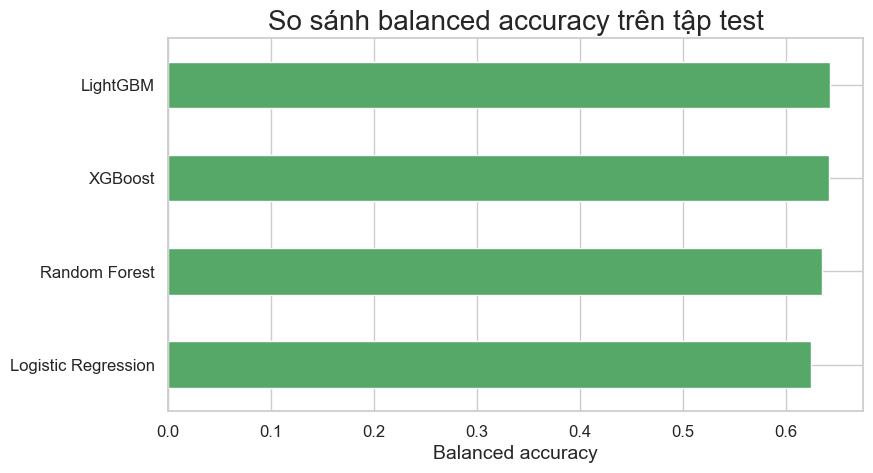

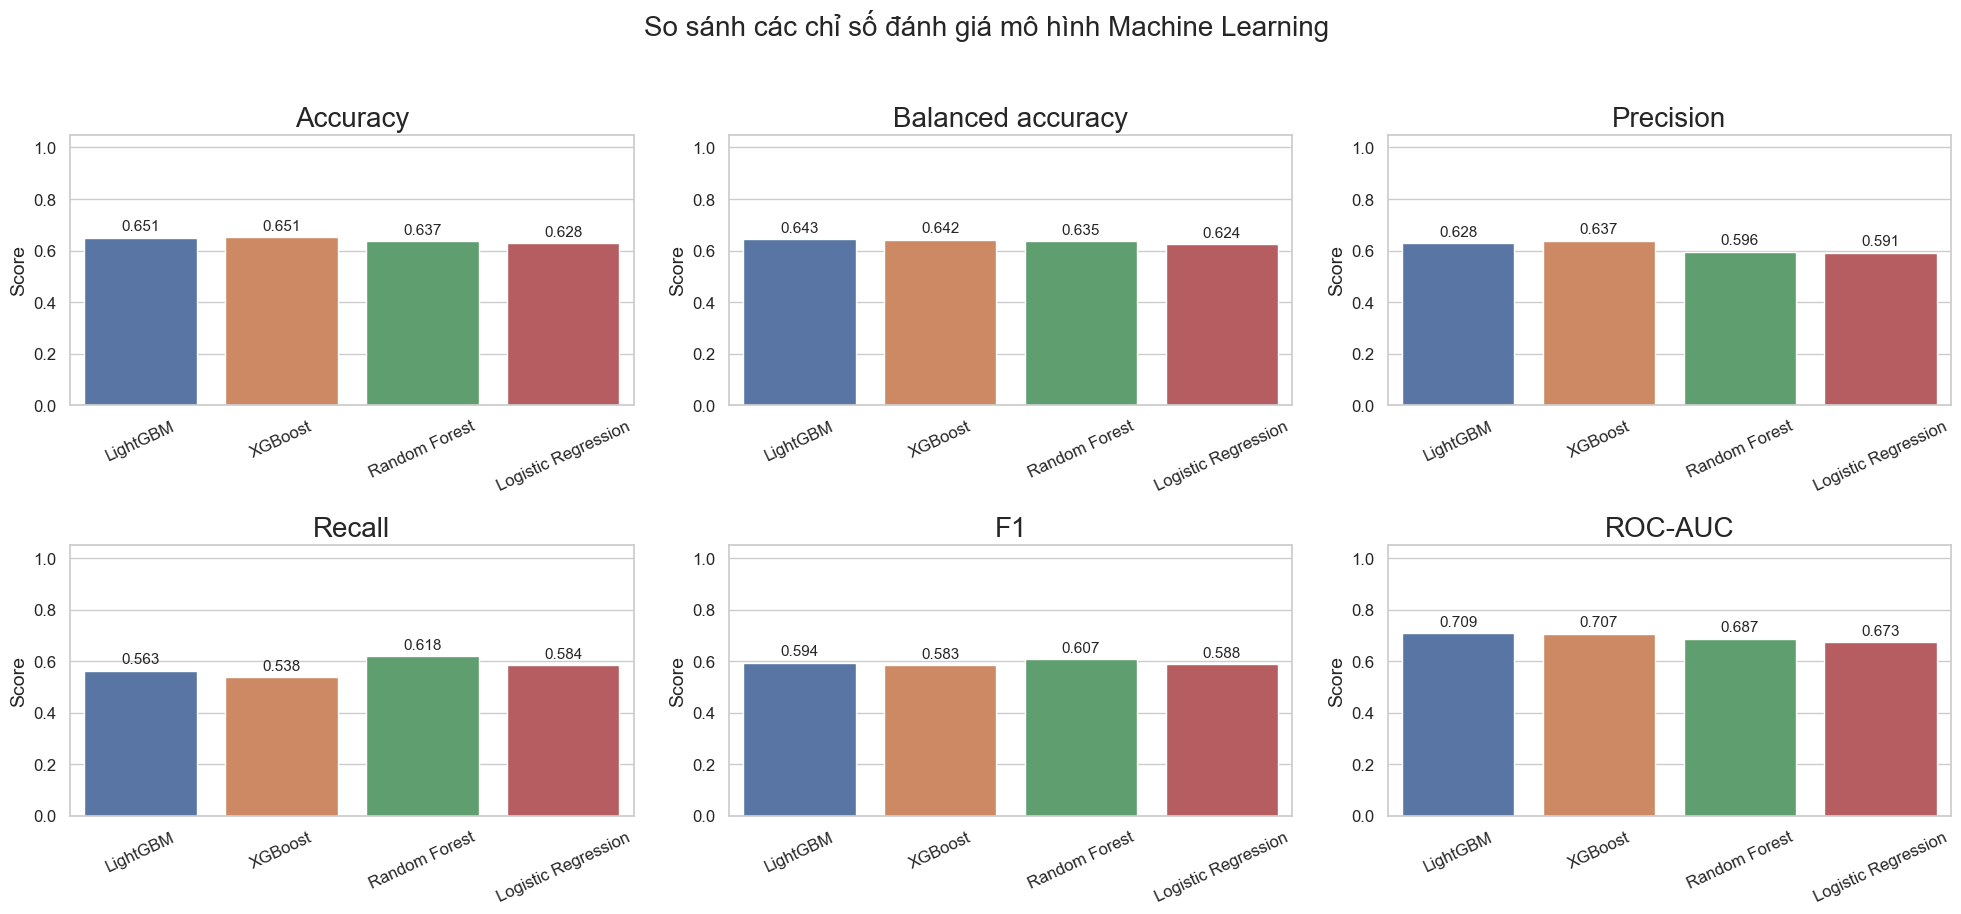

In [19]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
    ],
    sparse_threshold=0.3,
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, solver="liblinear", class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, max_depth=20, min_samples_leaf=2,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=250, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, tree_method="hist",
        eval_metric="logloss", n_jobs=-1, random_state=42,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=250, learning_rate=0.05, num_leaves=31,
        n_jobs=-1, verbosity=-1, random_state=42,
    ),
}

fitted_models = {}
model_results = []
for model_name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", estimator),
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    model_results.append({
        "Mô hình": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    })
    fitted_models[model_name] = pipeline
    print(f"Mô hình huấn luyện: {model_name}")

model_comparison = pd.DataFrame(model_results).sort_values(
    "Balanced accuracy", ascending=False
).reset_index(drop=True)
display(model_comparison.style.format({column: "{:.3f}" for column in model_comparison.columns[1:]}))

ax = model_comparison.set_index("Mô hình")["Balanced accuracy"].sort_values().plot(
    kind="barh", figsize=(9, 5), color=sns.color_palette("deep")[2]
)
ax.set_title("So sánh balanced accuracy trên tập test")
ax.set_xlabel("Balanced accuracy", fontsize=14)
ax.set_ylabel("", fontsize=14)
plt.tight_layout()
plt.show()

metrics = [
    "Accuracy",
    "Balanced accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

fig, axes = plt.subplots(2, 3, figsize=(20, 9))

for ax, metric in zip(axes.flat, metrics):
    sns.barplot(
        data=model_comparison,
        x="Mô hình",
        y=metric,
        ax=ax,
        hue="Mô hình",
        legend=False,
        palette="deep"
    )

    ax.set_title(metric, fontsize=20)
    ax.set_xlabel("")
    ax.set_ylabel("Score", fontsize=14)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=25, labelsize=12)
    ax.tick_params(axis="y", labelsize=12)

    # Hiển thị giá trị trên đầu cột
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3, fontsize=11)

plt.suptitle(
    "So sánh các chỉ số đánh giá mô hình Machine Learning",
    fontsize=20,
    y=1.02
)

plt.tight_layout()
plt.show()

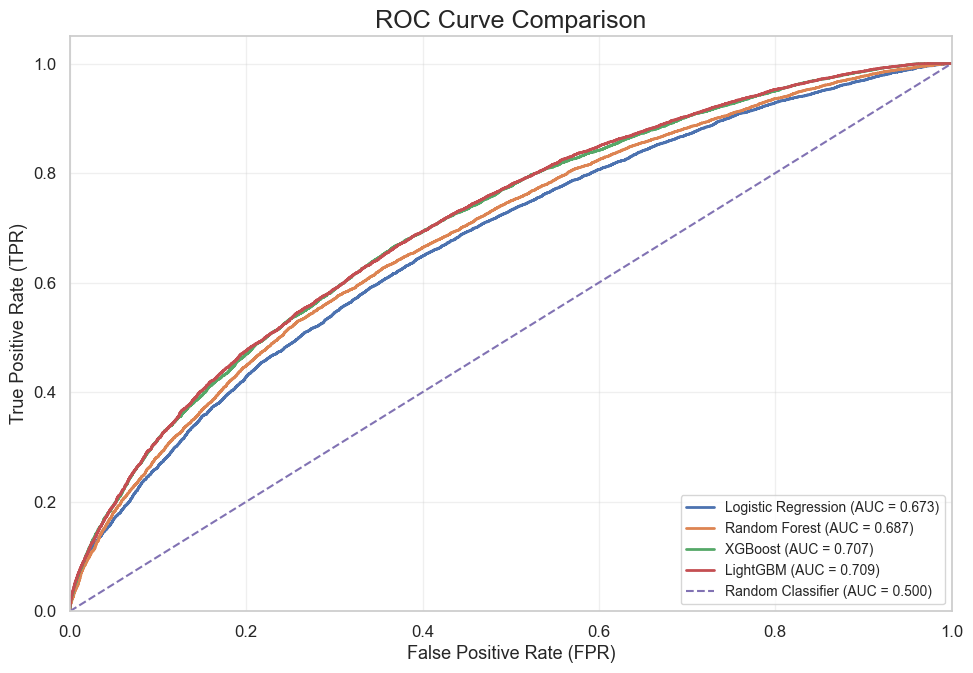

In [20]:

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for model_name, pipeline in fitted_models.items():

    # Lấy xác suất dự đoán thuộc class 1
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    # Tính False Positive Rate và True Positive Rate
    fpr, tpr, thresholds = roc_curve(y_test, probabilities)

    # Tính diện tích dưới đường ROC
    roc_auc = auc(fpr, tpr)

    # Vẽ đường ROC
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {roc_auc:.3f})"
    )

# Đường phân loại ngẫu nhiên
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.500)"
)

plt.title("ROC Curve Comparison", fontsize=18)
plt.xlabel("False Positive Rate (FPR)", fontsize=13)
plt.ylabel("True Positive Rate (TPR)", fontsize=13)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Thực hiện bằng LazyPredict


In [7]:
from lazypredict.Supervised import LazyClassifier

X_lazy_train, _, y_lazy_train, _ = train_test_split(
    X_train,
    y_train,
    train_size=min(8000, len(X_train) - 1),
    stratify=y_train,
    random_state=42,
)
X_lazy_test, _, y_lazy_test, _ = train_test_split(
    X_test,
    y_test,
    train_size=min(2000, len(X_test) - 1),
    stratify=y_test,
    random_state=42,
)

lazy_preprocessor = clone(preprocessor)
X_lazy_train_encoded = lazy_preprocessor.fit_transform(X_lazy_train, y_lazy_train)
X_lazy_test_encoded = lazy_preprocessor.transform(X_lazy_test)
if hasattr(X_lazy_train_encoded, "toarray"):
    X_lazy_train_encoded = X_lazy_train_encoded.toarray()
if hasattr(X_lazy_test_encoded, "toarray"):
    X_lazy_test_encoded = X_lazy_test_encoded.toarray()

lazy_classifier = LazyClassifier(verbose=0, ignore_warnings=True, predictions=False)
lazy_results, _ = lazy_classifier.fit(
    X_lazy_train_encoded,
    X_lazy_test_encoded,
    y_lazy_train,
    y_lazy_test,
)
display(lazy_results.sort_values("Balanced Accuracy", ascending=False).style.format("{:.3f}"))

c:\Users\skyge\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
High-dimensional dataset (1499 features). Some models may be slow or fail. Consider dimensionality reduction.


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
LGBMClassifier,0.621,0.613,0.661,0.619,0.619,0.621,0.969
RandomForestClassifier,0.620,0.607,0.656,0.612,0.617,0.620,5.379
AdaBoostClassifier,0.621,0.603,0.649,0.605,0.621,0.621,4.879
XGBClassifier,0.602,0.593,0.642,0.598,0.598,0.602,0.999
BernoulliNB,0.593,0.588,0.620,0.592,0.592,0.593,0.592
ExtraTreesClassifier,0.594,0.582,0.630,0.587,0.590,0.594,13.475
NearestCentroid,0.578,0.576,0.613,0.579,0.580,0.578,0.675
BaggingClassifier,0.586,0.572,0.619,0.577,0.581,0.586,4.855
CalibratedClassifierCV,0.590,0.566,0.595,0.559,0.590,0.590,29.201
